# IND320- Project Work Part 3
**Student:** Sania Minaipour

### Links
- GitHub repository: https://github.com/Saniami/IND320-project
- Streamlit app: https://ind320-project-697hjpoelth3xk2xbtm6tk.streamlit.app/



## AI Usage

In this part i still used Claude to help me to write the code, especially in utils.py. In the notebook it helped me with the functions for SPC, LOF, STL and the spectrogram, and with how to join the NVE regions into the VASS areas. It was also really useful when things went wrong, for example when the app could not find statsmodels because I had two Python environments, and when the weather page was really slow because I had used up the open-meteo limit.

Like earlier i ran all the code myself and looked at the plots to see if they made sens. Some things I decided myself,like adding rain and snowfall, choosing my own values for the seasonal smoother and the overlap, and
putting the area selector on the pages instead of in the sidebar. When I got an error, I read it and
tried to understand what was wrong before I fixed it.

I also used Claude for the text. It helped me with spelling and grammar, and it wrote first drafts of
some of the text in the notebook and the log, which I then changed to fit what i actually did.

### Setup

In [21]:
# Libraries used in this notebook
import time, math
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import requests
import matplotlib.pyplot as plt
from scipy.fft import dct, idct
from scipy.signal import spectrogram
from sklearn.neighbors import LocalOutlierFactor
from statsmodels.tsa.seasonal import STL


## Regions from NVE Atlas
The shapefiles are from https://atlas.nve.no:
- **Budområder**: the five price areas NO 1-5, which are the EL areas in Magasinstatistikk.
- **NVE_Region**: five NVE regions (RV, RM, RN, RØ, RS). As given in the task, East = RS + RØ and North = RM + RN.

The reservoir data only has VASS 1-3, so i combined the VASS areas from NVE regions like:
- VASS 1 (Sørøst) = RS + RØ
- VASS 2 (Vest) = RV
- VASS 3 (Midt/Nord) = RM + RN.

In [ ]:
DATA_DIR = "../data"

# The shapefiles are in different map projections, Both use EPSG:25833 (metres).
# utf-8 is needed because of the Norwegian letter in the names.
bud = gpd.read_file(f"{DATA_DIR}/Budområder/Budområder.shp", encoding="utf-8")
reg = gpd.read_file(f"{DATA_DIR}/NVE region/NVE_Region.shp", encoding="utf-8")

print(bud.crs, bud["budomr"].tolist())
print(reg.crs, reg["REGION"].tolist())


EPSG:25833 ['NO 1', 'NO 2', 'NO 3', 'NO 4', 'NO 5']
EPSG:25833 ['RV', 'RM', 'RN', 'RØ', 'RS']


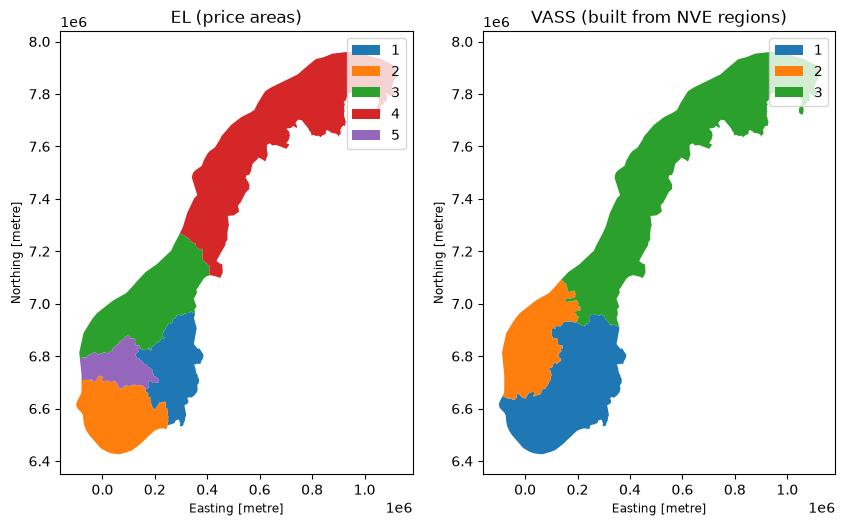

In [23]:
# Which NVE regions make up each VASS area
VASS_MAP = {1: ["RS", "RØ"], 2: ["RV"], 3: ["RM", "RN"]}

# One table of polygons with the same keys (Area_Type, Area_Number) as the reservoir data
rows = []
for _, r in bud.iterrows():                                   # EL 1-5
    rows.append({"Area_Type": "EL", "Area_Number": int(r["budomr"][-1]), "geometry": r.geometry})
for nr, codes in VASS_MAP.items():                            # VASS 1-3
    rows.append({"Area_Type": "VASS", "Area_Number": nr,
                 "geometry": reg[reg["REGION"].isin(codes)].union_all()})
rows.append({"Area_Type": "NO", "Area_Number": 0, "geometry": bud.union_all()})  # whole country
areas_gdf = gpd.GeoDataFrame(rows, crs=bud.crs)

# Quick map to check that the areas look right
fig, axs = plt.subplots(1, 2, figsize=(10, 6))
areas_gdf[areas_gdf.Area_Type == "EL"].plot(column="Area_Number", categorical=True, legend=True, ax=axs[0])
areas_gdf[areas_gdf.Area_Type == "VASS"].plot(column="Area_Number", categorical=True, legend=True, ax=axs[1])
axs[0].set_title("EL (price areas)"); axs[1].set_title("VASS (built from NVE regions)")
plt.show()

## 1000 Random samples

In [24]:
N_POINTS = 1000 # Number of random points we want in each area.
SEED = 320 # starting point for the random number generator, so that we get the same points each time we run this code.

pts = []
for i, a in areas_gdf.iterrows():
    p = gpd.GeoSeries([a.geometry], crs=areas_gdf.crs).sample_points(N_POINTS, rng=SEED + i)
    p = p.explode(index_parts=False).to_crs(4326)             # MultiPoint -> points, metres -> lon/lat
    pts.append(pd.DataFrame({"Area_Type": a["Area_Type"], "Area_Number": a["Area_Number"],
                             "lon": p.x.values, "lat": p.y.values}))
    
locations = pd.concat(pts, ignore_index=True)
locations.to_csv("../data/locations.csv", index=False)               # also used by the Streamlit app
print(locations.groupby(["Area_Type", "Area_Number"]).size())

Area_Type  Area_Number
EL         1              1000
           2              1000
           3              1000
           4              1000
           5              1000
NO         0              1000
VASS       1              1000
           2              1000
           3              1000
dtype: int64


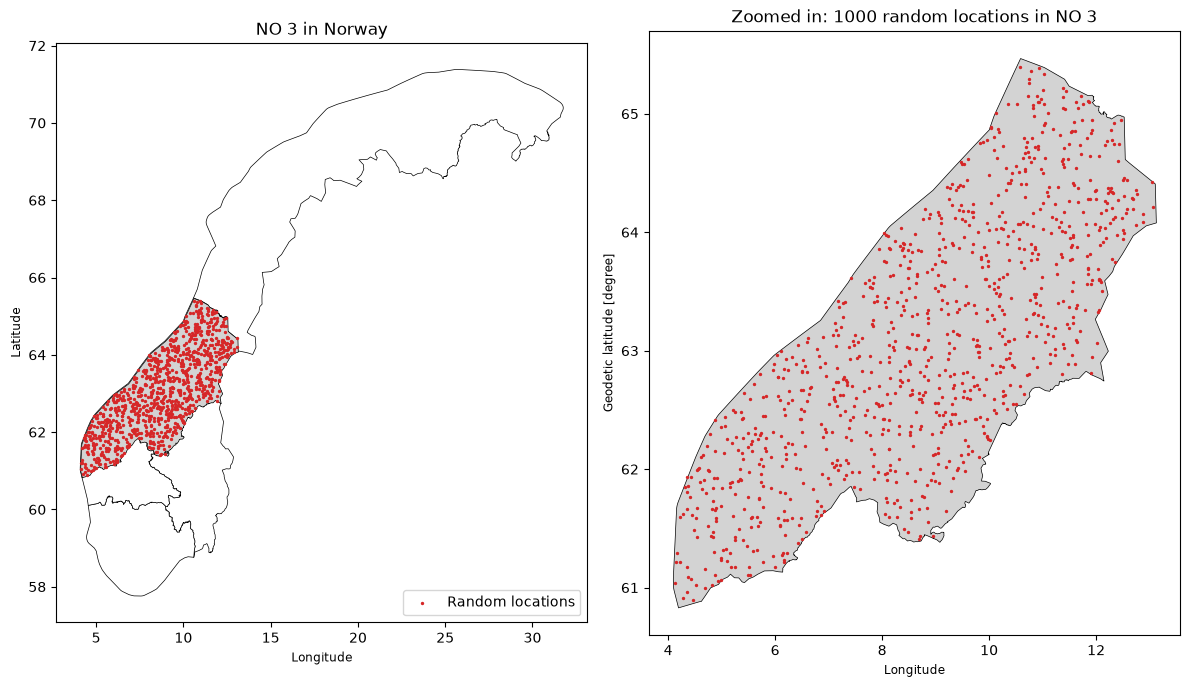

In [25]:
# To check that the random points really are inside the polygon, plot them on a map.

# Left: whole country with all price areas, NO 3 in grey. Right: zoomed in on NO 3.
el = areas_gdf[areas_gdf.Area_Type == "EL"].to_crs(4326)                      # all EL areas, in lon/lat like the points. 4326 is the EPSG code for WGS84, which is the standard lon/lat coordinate system.
sel = locations[(locations.Area_Type == "EL") & (locations.Area_Number == 3)]  # the points for NO 3

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 8))

# Left: whole map, NO 3 highlighted
el.plot(color="white", edgecolor="black", linewidth=0.5, ax=ax1)
el[el.Area_Number == 3].plot(color="lightgrey", edgecolor="black", linewidth=0.5, ax=ax1)
ax1.scatter(sel.lon, sel.lat, s=2, color="tab:red", label="Random locations")
ax1.set_title("NO 3 in Norway")
ax1.set_xlabel("Longitude"); ax1.set_ylabel("Latitude")
ax1.legend(loc="lower right")

# Right: zoomed in on NO 3
el[el.Area_Number == 3].plot(color="lightgrey", edgecolor="black", linewidth=0.5, ax=ax2)
ax2.scatter(sel.lon, sel.lat, s=2, color="tab:red")
ax2.set_title("Zoomed in: 1000 random locations in NO 3")
ax2.set_xlabel("Longitude")

plt.tight_layout()
plt.show()

## Weatherdata from open-meteo

The function takes an area (type + number) and a time interval, looks up the 1000 locations for that area and
downloads hourly ERA5 reanalysis data from the archive API.

ERA5 has a 0.25° grid, so many of the 1000 points fall in the same grid cell. The function snaps each point to its
grid cell, downloads each unique cell once, and weights each cell by the number of points in it. This gives the same
area average as downloading all 1000 points, but with far fewer API calls. Several cells are sent in each request,
and the result is cached to disk.

Variables: temperature, precipitation, wind speed, wind gusts, wind direction, rain and snowfall.

In [26]:
ARCHIVE_URL = "https://archive-api.open-meteo.com/v1/archive"
HOURLY = ["temperature_2m", "precipitation", "rain", "snowfall","wind_speed_10m", "wind_gusts_10m", "wind_direction_10m"] # also added rain and snowfall 
CACHE = Path("../data/weather_cache"); CACHE.mkdir(exist_ok=True)

def download_weather(area_type, area_number, start, end, batch=50):
    """Hourly ERA5 data for one area, averaged over its random locations.
    area_type, area_number: e.g. ("EL", 3) for NO3.  start, end: "YYYY-MM-DD".
    Returns a DataFrame indexed by UTC time with one column per variable."""

    cache_file = CACHE / f"{area_type}{area_number}_{start}_{end}.csv"
    if cache_file.exists():                                   # already downloaded
        return pd.read_csv(cache_file, index_col="time", parse_dates=True)

    # Look up the points for this area and snap them to the ERA5 grid (0.25°)
    loc = locations[(locations.Area_Type == area_type) & (locations.Area_Number == area_number)]
    cells = (loc.assign(lat=(loc.lat * 4).round() / 4, lon=(loc.lon * 4).round() / 4)
                .groupby(["lat", "lon"]).size().rename("weight").reset_index())
    print(f"{area_type} {area_number}: {len(loc)} points -> {len(cells)} grid cells")

    frames = []
    for i in range(0, len(cells), batch):                     # several locations per request
        part = cells.iloc[i:i + batch]
        params = {"latitude": ",".join(map(str, part.lat)), "longitude": ",".join(map(str, part.lon)),
                  "start_date": start, "end_date": end, "hourly": ",".join(HOURLY),
                  "models": "era5", "timezone": "UTC"}
        for attempt in range(5):                              # wait and retry if rate-limited (HTTP 429)
            r = requests.get(ARCHIVE_URL, params=params, timeout=180)
            if r.status_code != 429:
                break
            time.sleep(60)
        r.raise_for_status()
        js = r.json()
        js = js if isinstance(js, list) else [js]             # a single location returns a dict
        for w, j in zip(part.weight, js):
            f = pd.DataFrame(j["hourly"]); f["weight"] = w
            frames.append(f)
        time.sleep(1)

    # Weighted average over the grid cells
    d = pd.concat(frames); d["time"] = pd.to_datetime(d["time"])
    rad = np.deg2rad(d["wind_direction_10m"])                 # direction is averaged as a vector, not in degrees
    d["u"], d["v"] = np.sin(rad), np.cos(rad)
    cols = [c for c in HOURLY if c != "wind_direction_10m"] + ["u", "v"]
    out = (d[cols].mul(d["weight"], axis=0).groupby(d["time"]).sum()
              .div(d.groupby("time")["weight"].sum(), axis=0))
    out["wind_direction_10m"] = np.rad2deg(np.arctan2(out.pop("u"), out.pop("v"))) % 360
    out.to_csv(cache_file)
    return out

In [27]:
# Download NO3 (EL 3) for 2024
no3 = download_weather("EL", 3, "2024-01-01", "2024-12-31")
print(no3.shape)
no3.describe().round(2)

(8784, 7)


,temperature_2m,precipitation,rain,snowfall,wind_speed_10m,wind_gusts_10m,wind_direction_10m
count,8784.00,8784.00,8784.00,8784.00,8784.00,8784.00,8784.00
mean,5.80,0.20,0.17,0.02,14.91,31.32,183.29
std,6.62,0.27,0.24,0.05,5.89,13.11,80.80
min,-11.31,0.00,0.00,0.00,3.64,8.64,0.04
25%,1.32,0.02,0.01,0.00,10.47,21.69,131.37
50%,5.44,0.10,0.07,0.00,13.77,28.71,175.37
75%,11.06,0.29,0.24,0.02,18.40,37.83,241.54
max,22.26,2.67,2.03,0.90,46.09,105.62,359.79


## Outliers and anomalies
### Precipitation: DCT and Statistical Process Control

Precipitation changes with the seasons, so a value that is normal in autumn can be unusual in summer.
To find the real outliers, I first remove the slow seasonal pattern and only look at what is left.

I do this with the Discrete Cosine Transform (DCT). The DCT splits the series into slow and fast variations.
I keep only the fast part and remove the slow part, which is the season. What is left is the seasonally
adjusted variation (SATV).

Then I calculate the limits for normal values. I use the median and the MAD instead of the mean and the
standard deviation, because they are not pulled up by a few very large values. The limits follow the seasonal
level, so they are drawn as curves around the precipitation. Points outside the limits are outliers and are
shown in red. The SATV itself is only used to find the limits, and is not plotted.

The function has two parameters:
- `freq_cutoff`: how slow a variation has to be to count as season. The default is 1/30 cycles per day, so
  everything slower than about a month is removed.
- `n_std`: how wide the limits are. The default is 3 standard deviations.

In [28]:
def spc_outliers(s, freq_cutoff=1/30, n_std=3.0, title="Precipitation"):
    """SPC outliers based on DCT high-pass filtered data (SATV).
    s: hourly series.  freq_cutoff: cycles per day.  n_std: number of robust standard deviations.
    Returns (fig, summary dict, DataFrame with the outliers)."""
    x = s.to_numpy(dtype=float)
    n = len(x)
    c = dct(x, norm="ortho")
    k = int(math.ceil(2 * n * freq_cutoff / 24))              # index of the cut-off frequency
    c_low = c.copy(); c_low[k:] = 0                           # keep only the slow part
    seasonal = idct(c_low, norm="ortho")                      # low-pass = seasonal level
    satv = x - seasonal                                       # high-pass = SATV

    med = np.median(satv)
    sigma = 1.4826 * np.median(np.abs(satv - med))            # robust standard deviation (MAD)
    upper = seasonal + med + n_std * sigma
    lower = seasonal + med - n_std * sigma
    is_out = (x > upper) | (x < lower)

    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(s.index, x, lw=0.6, color="tab:blue", label=title)
    ax.plot(s.index, upper, color="black", lw=1, ls="--", label=f"SPC limits (±{n_std}σ)")
    ax.plot(s.index, lower, color="black", lw=1, ls="--")
    ax.scatter(s.index[is_out], x[is_out], s=8, color="tab:red", zorder=3, label="Outliers")
    ax.set_xlabel("Time"); ax.set_ylabel(title); ax.legend(loc="upper right")
    ax.set_title(f"{title} with SPC limits (cut-off {freq_cutoff:.3g} cycles/day)")
    fig.tight_layout()

    outliers = pd.DataFrame({"value": x[is_out], "upper": upper[is_out], "lower": lower[is_out]},
                            index=s.index[is_out])
    summary = {"n_points": n, "n_outliers": int(is_out.sum()),
               "share_outliers_%": float(round(100 * is_out.mean(), 2)),
               "n_above": int((x > upper).sum()), "n_below": int((x < lower).sum()),
               "median_satv": float(round(med, 4)), "robust_sigma": float(round(sigma, 4))}
    return fig, summary, outliers

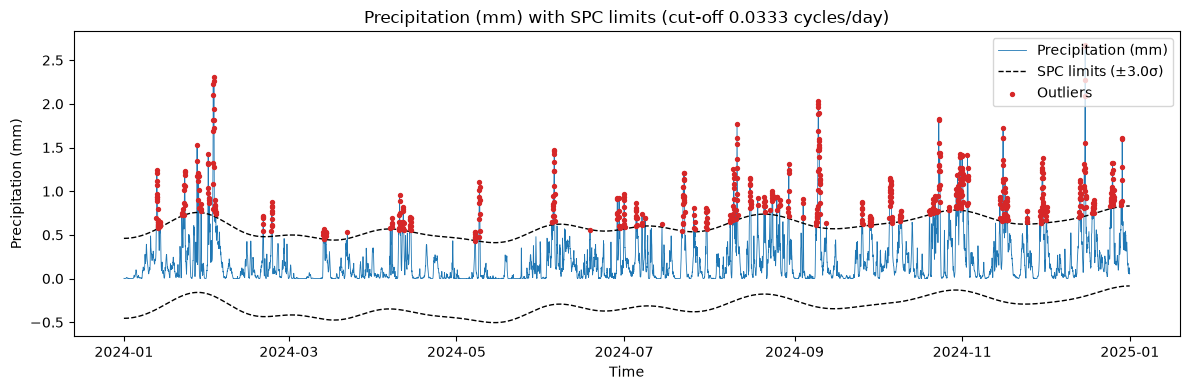

{'n_points': 8784, 'n_outliers': 653, 'share_outliers_%': 7.43, 'n_above': 653, 'n_below': 0, 'median_satv': -0.0645, 'robust_sigma': 0.1525}


,value,upper,lower
time,,,
2024-12-15 18:00:00,2.6712,0.714499,-0.200597
2024-12-15 17:00:00,2.6637,0.714143,-0.200953
2024-02-02 18:00:00,2.3112,0.713586,-0.201510
2024-12-15 19:00:00,2.2676,0.714856,-0.200240
2024-02-02 17:00:00,2.2670,0.714166,-0.200930
2024-02-02 12:00:00,2.2262,0.717019,-0.198077
2024-02-02 13:00:00,2.0967,0.716455,-0.198641
2024-12-15 16:00:00,2.0882,0.713788,-0.201308
2024-09-09 17:00:00,2.0290,0.586602,-0.328494


In [29]:
# Test with the defaults
fig, summary, out_spc = spc_outliers(no3["precipitation"], title="Precipitation (mm)")
plt.show()
print(summary)
out_spc.sort_values("value", ascending=False).head(10)

#### Testing with other parameters

Here I run the function again with different values, to check that the parameters work and to see how
they change the result. I use a lower cut-off (1/90 cycles per day), so only variations slower than about
three months count as season. I also make the limits wider (4 standard deviations instead of 3).
Wider limits should give fewer outliers than the first test.

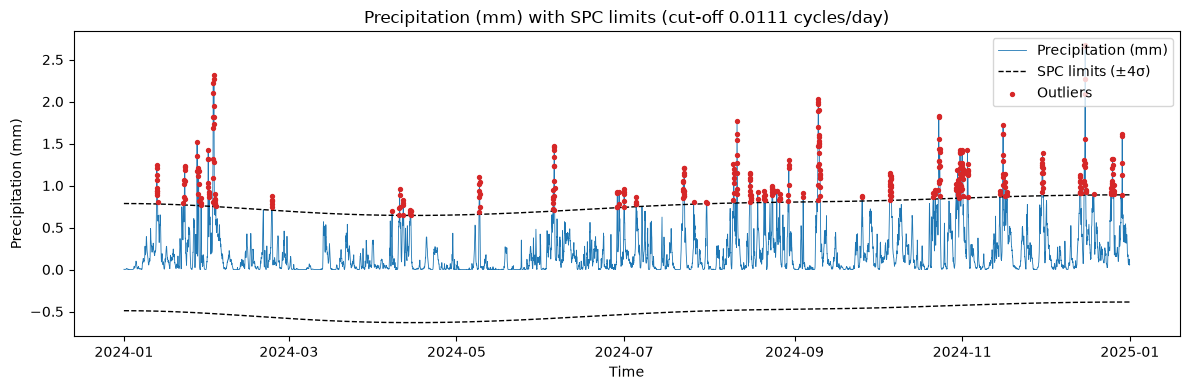

{'n_points': 8784, 'n_outliers': 382, 'share_outliers_%': 4.35, 'n_above': 382, 'n_below': 0, 'median_satv': -0.08, 'robust_sigma': 0.1595}


In [30]:
fig, summary, _ = spc_outliers(no3["precipitation"], freq_cutoff=1/90, n_std=4, title="Precipitation (mm)")
plt.show()
print(summary)

#### Comment on the results

All outliers are above the upper limit, since precipitation can never be below zero. They come in groups,
because one rain event lasts several hours. With 1/90 cycles per day and 4 standard deviations, the limits are
smoother and higher, so there are fewer outliers and only the biggest rain events are left.

### Temperature: Local Outlier Factor

For temperature I use the Local Outlier Factor (LOF) method. LOF looks at each point and its closest
neighbours. If a point is far away from its neighbours, compared to how close the neighbours are to each
other, it is marked as an anomaly.

In this part LOF looks at: the time and the temperature. Both are scaled so they count equally.
This way each hour is compared with the hours around it, and not with the whole year. A temperature of
-10 °C is normal in January, but it would be very strange in July, and LOF can see this difference.

The function has one main parameter, `contamination`, which is the share of points that are marked as
anomalies.

In [31]:
def lof_anomalies(s, contamination=0.01, n_neighbors=50, title="Temperature"):
    """Anomalies with Local Outlier Factor.
    s: hourly series.  contamination: share of points marked as outliers.
    Returns (fig, summary dict, DataFrame with the anomalies)."""
    s = s.dropna()
    t = (s.index - s.index[0]).total_seconds().to_numpy()
    X = np.column_stack([(t - t.mean()) / t.std(), (s - s.mean()) / s.std()])   # standardised time and value
    lof = LocalOutlierFactor(n_neighbors=n_neighbors, contamination=contamination)
    is_out = lof.fit_predict(X) == -1
    score = -lof.negative_outlier_factor_                     # higher = more anomalous

    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(s.index, s, lw=0.6, color="tab:blue", label=title)
    ax.scatter(s.index[is_out], s[is_out], s=10, color="tab:red", zorder=3, label="LOF anomalies")
    ax.set_xlabel("Time"); ax.set_ylabel(title); ax.legend(loc="upper right")
    ax.set_title(f"{title} with LOF anomalies ({contamination:.1%})")
    fig.tight_layout()

    anomalies = pd.DataFrame({"value": s[is_out], "lof_score": score[is_out]}).sort_values("lof_score", ascending=False)
    summary = {"n_points": len(s), "n_anomalies": int(is_out.sum()),
               "share_anomalies_%": float(round(100 * is_out.mean(), 2)),
               "mean_value_anomalies": float(round(s[is_out].mean(), 2)), "mean_value_all": float(round(s.mean(), 2))}
    return fig, summary, anomalies

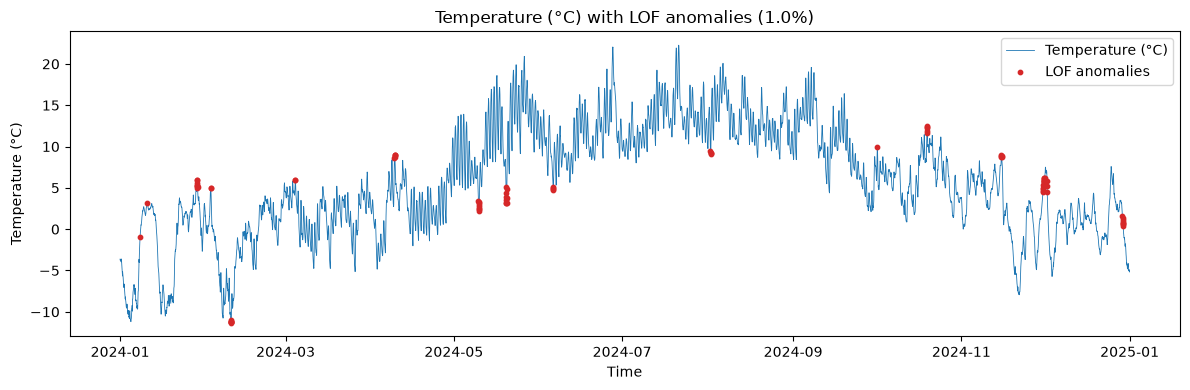

{'n_points': 8784, 'n_anomalies': 88, 'share_anomalies_%': 1.0, 'mean_value_anomalies': 4.2, 'mean_value_all': 5.8}


,value,lof_score
time,,
2024-10-19 13:00:00,12.4496,2.178768
2024-10-19 12:00:00,12.2326,2.171224
2024-10-19 14:00:00,12.3487,2.147469
2024-05-20 02:00:00,3.1314,2.042064
2024-05-20 03:00:00,3.1800,2.001837
2024-05-20 01:00:00,3.2243,1.984168
2024-10-19 15:00:00,11.9235,1.945805
2024-01-28 22:00:00,5.9615,1.836820
2024-01-28 23:00:00,5.9991,1.836142


In [32]:
# Test with the default 1 %
fig, summary, out_lof = lof_anomalies(no3["temperature_2m"], title="Temperature (°C)")
plt.show()
print(summary)
out_lof.head(10)

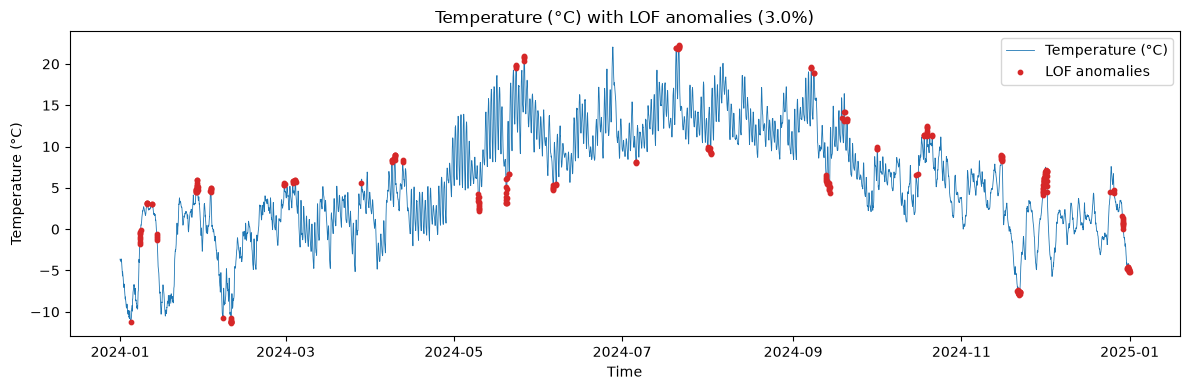

{'n_points': 8784, 'n_anomalies': 264, 'share_anomalies_%': 3.01, 'mean_value_anomalies': 4.91, 'mean_value_all': 5.8}


In [33]:
# Test with 3 % outliers
fig, summary, _ = lof_anomalies(no3["temperature_2m"], contamination=0.03, title="Temperature (°C)")
plt.show()
print(summary)

## Reservoir data (Magasinstatistikk)
The same download as in part 2. STL and the spectrogram use the degree of filling (`Fill_Percentage`) for one area.

In [34]:
BASE = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk"
r = requests.get(f"{BASE}/HentOffentligData", headers={"Accept": "application/json"}, timeout=120)
r.raise_for_status()
res = (pd.DataFrame(r.json())
         .rename(columns={"dato_Id": "Date", "omrType": "Area_Type", "omrnr": "Area_Number",
                          "fyllingsgrad": "Fill_Percentage"}))
res["Date"] = pd.to_datetime(res["Date"]) # convert to datetime
res = res.sort_values(["Area_Type", "Area_Number", "Date"]) # sort by area and then date

def fill_series(area_type="EL", area_number=3):
    """Weekly degree of filling for one area as a time series."""
    d = res[(res.Area_Type == area_type) & (res.Area_Number == area_number)]
    return d.set_index("Date")["Fill_Percentage"].asfreq("W-SUN", method="ffill")   # regular weekly steps

# Tries to get the series for NO3(EL 3), the same as the weather data
fill = fill_series("EL", 3)
print(fill.index.min(), fill.index.max(), len(fill))

1995-01-08 00:00:00 2026-11-01 00:00:00 1661


## Seasonal-Trend decomposition using LOESS (STL)

STL splits the fill percentage into three parts: a slow trend, a seasonal pattern that repeats every year,
and the rest (residual), which is what neither the trend nor the season can explain.
The data has one value per week and the pattern repeats every year, so I use `period = 52`.

The function has three parameters:
- `seasonal`: how smooth the seasonal pattern is. The default is 17. A higher number lets the
  season change less from year to year.
- `trend`: how smooth the trend is. The default is 105 weeks, about two years, so the trend only shows
  slow changes over several years.
- `robust`: if this is True, single weeks with very unusual values have less effect on the trend and
  the season. The default is True.

Both smoothers must be odd numbers, and the trend must be longer than the period.

In [35]:
def stl_plot(s, period=52, seasonal=17, trend=105, robust=True, title="Fill percentage"):
    """STL decomposition. Returns the figure with observed, trend, seasonal and residual."""
    res_stl = STL(s, period=period, seasonal=seasonal, trend=trend, robust=robust).fit()
    fig, axs = plt.subplots(4, 1, figsize=(12, 8), sharex=True)
    parts = [("Observed", res_stl.observed), ("Trend", res_stl.trend),
             ("Seasonal", res_stl.seasonal), ("Residual", res_stl.resid)]
    for ax, (name, y) in zip(axs, parts):
        if name == "Residual":
            ax.scatter(s.index, y, s=3)
            ax.axhline(0, color="black", lw=0.8)
        else:
            ax.plot(s.index, y)
        ax.set_ylabel(name)
    axs[0].set_title(f"STL of {title} (seasonal={seasonal}, trend={trend}, robust={robust})")
    axs[-1].set_xlabel("Date")
    fig.tight_layout()
    return fig

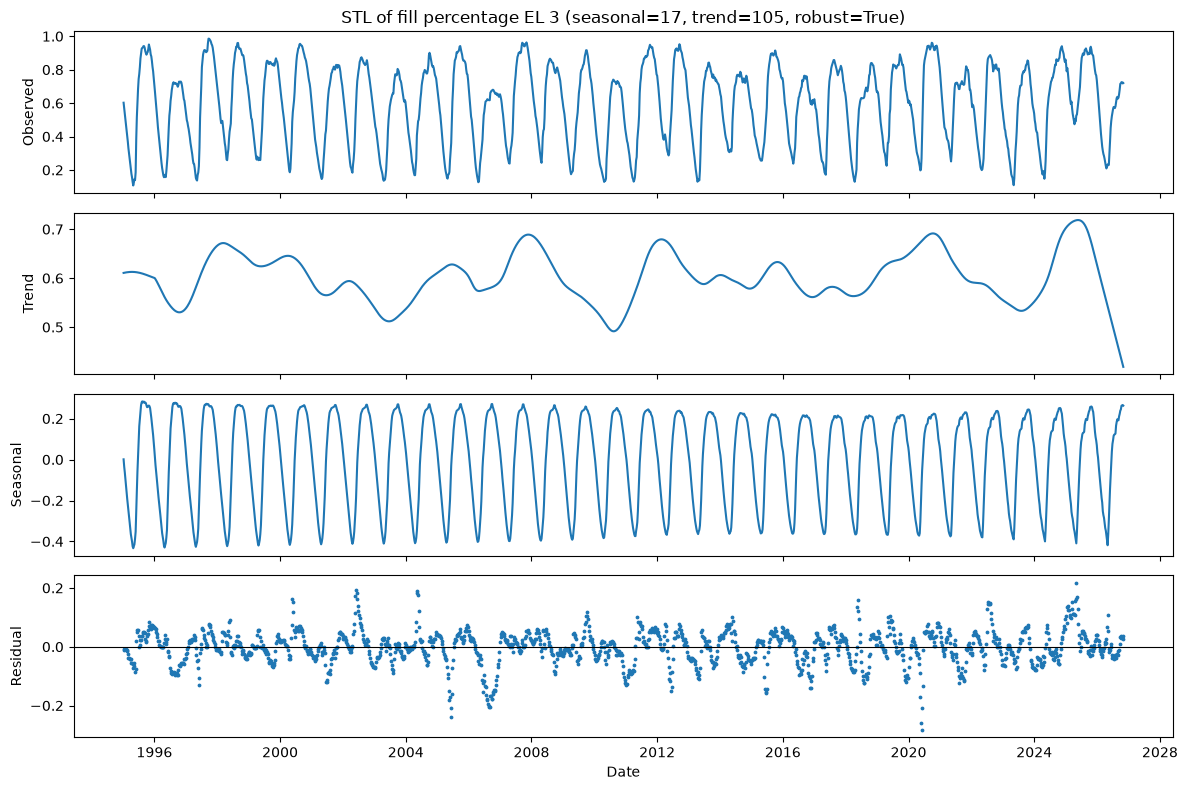

In [36]:
# Test with the defaults
fig = stl_plot(fill, title="fill percentage EL 3")
plt.show()

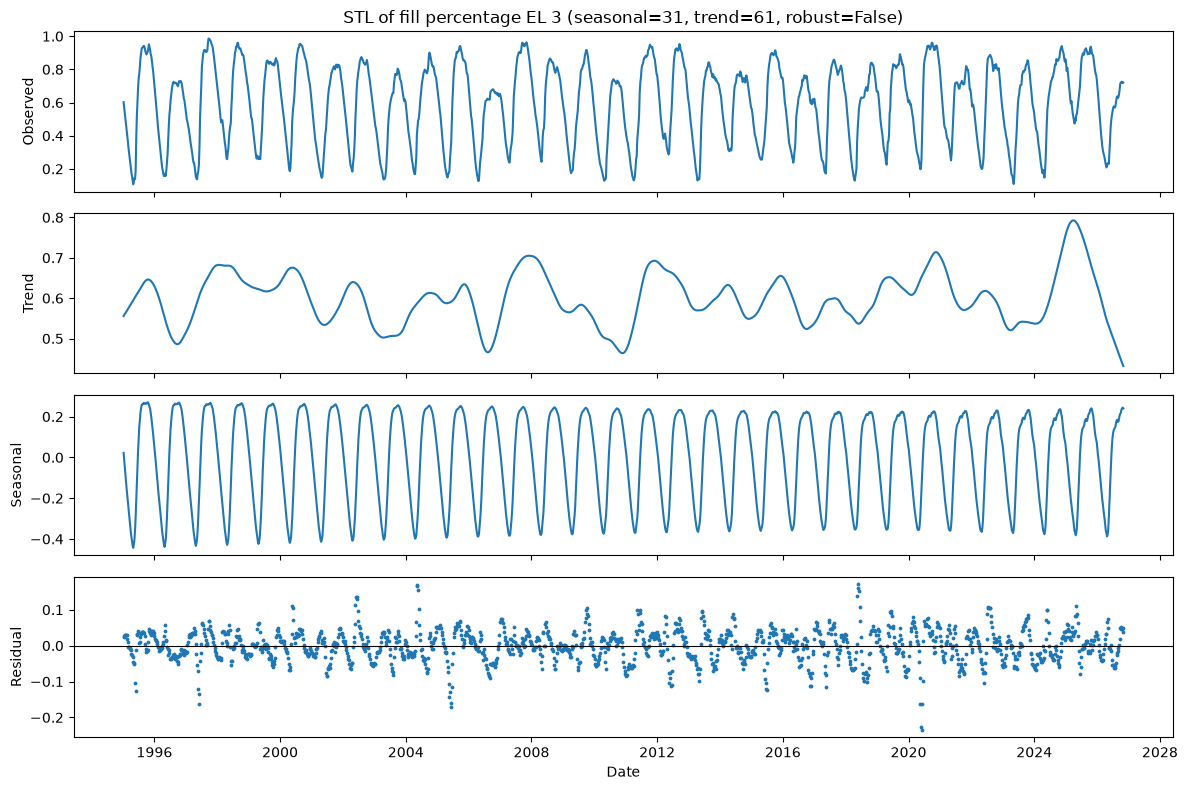

In [37]:
# Test with other parameters: a stiffer season, a shorter trend and no robust fitting
fig = stl_plot(fill, seasonal=31, trend=61, robust=False, title="fill percentage EL 3")
plt.show()

## Spectrogram

A spectrogram shows which repeating patterns there are in the fill percentage, and how they change
over time. The data is cut into windows, and for each window I check which frequencies are strong.
The data has one value per week, so the frequency axis is in cycles per year. A strong band at 1 means
a pattern that repeats once a year.

The function has two parameters:
- `window_length`: how many weeks each window has. The default is 104 weeks (two years), so the yearly
  pattern is seen twice in each window.
- `window_overlap`: how many weeks two windows share. The default is 73 weeks, which is about 70 %.
  More overlap gives a smoother picture over time.

In [38]:
def spectrogram_plot(s, window_length=104, window_overlap=73, title="Fill percentage"):
    """Spectrogram of a weekly series. Returns the figure."""
    fs = 52.0                                                  # samples per year
    f, t, Sxx = spectrogram(s.to_numpy(dtype=float), fs=fs, window="hann",
                            nperseg=window_length, noverlap=window_overlap, detrend="constant")
    times = s.index[0] + pd.to_timedelta(t * 365.25, unit="D")  # window centres as dates
    fig, ax = plt.subplots(figsize=(12, 4))
    m = ax.pcolormesh(times, f, 10 * np.log10(Sxx + 1e-12), shading="auto", cmap="viridis")
    fig.colorbar(m, ax=ax, label="Power (dB)")
    ax.set_ylabel("Frequency (cycles per year)"); ax.set_xlabel("Date")
    ax.set_title(f"Spectrogram of {title} (window {window_length}, overlap {window_overlap})")
    fig.tight_layout()
    return fig

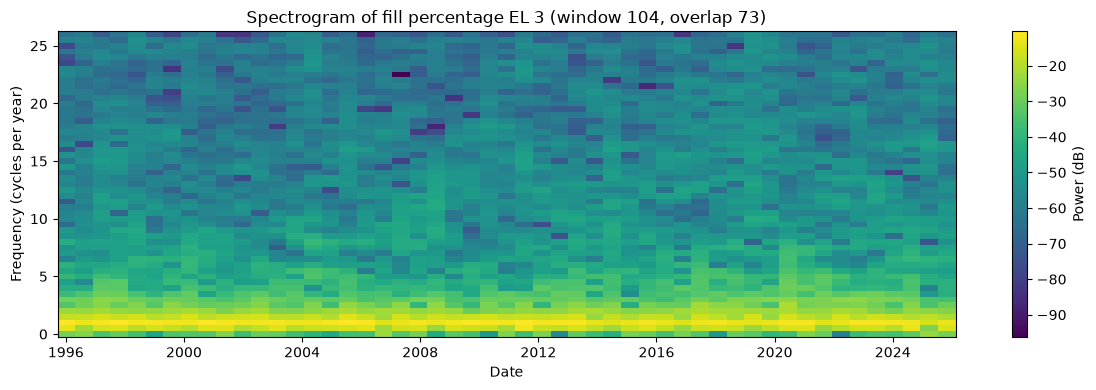

In [39]:
# Test with the defaults
fig = spectrogram_plot(fill, title="fill percentage EL 3")
plt.show()

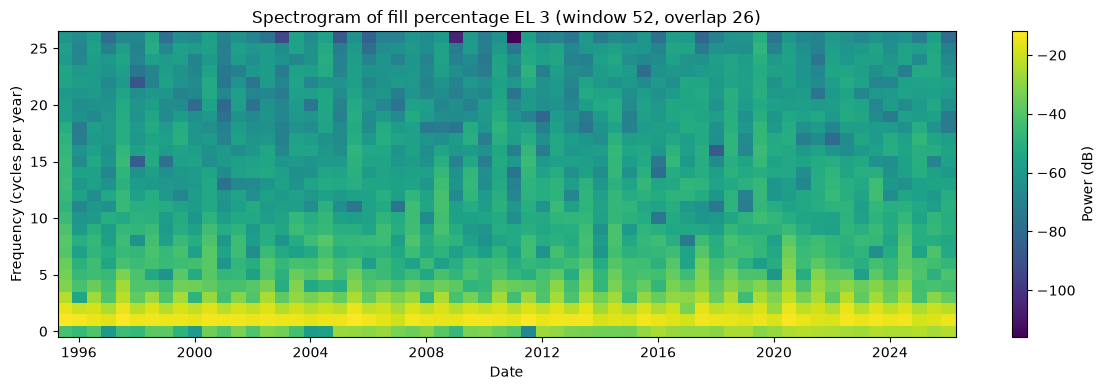

In [40]:
# Test with a shorter window: better time resolution, worse frequency resolution
fig = spectrogram_plot(fill, window_length=52, window_overlap=26, title="fill percentage EL 3")
plt.show()

## Log

In part 3 I added weather data and some new analyses of the data. Unlike part 2, where most of the work
was the setup, this time most of the work was to understand the methods and how to use them in the app.

First I downloaded two shapefiles from NVE Atlas. The price areas matched the EL areas directly.
However, the VASS areas I had to make myself by joining some of the NVE regions together, so that East
is RS + RØ and North is RM + RN. In the end this gave three areas, which fits with the reservoir data,
since it only has VASS 1-3.

Then I picked 1000 random points in each area. Because the weather data comes in squares of about 30 km,
many of the points end up in the same square. So instead of downloading the same thing many times, I
download each square only once. I also added rain and snowfall, because snow stays on the ground until
spring, and that affects how full the reservoirs are.

For precipitation I first removed the seasonal pattern, and then I looked for hours with much more rain
than normal. All the outliers were above the upper limit, because it can never rain less than zero.
For temperature I used LOF instead, which compares each hour with the hours around it. Unlike the
precipitation method, LOF does not use limits. Instead, it marks out the hours that stand out the most.

The STL and the spectrogram use the reservoir fill percentage instead of the weather. Here I chose my
own values, for example 17 for the seasonal smoother and about 70 % overlap.

The Streamlit part took longer than I expected. I put the shared code in one file, so every page uses
the same area selector. The area is saved, so if I choose an area on one page, the other pages follow.
At first the selector was in the sidebar, however I moved it onto the pages, because I think it is
easier to see there. On the data table and plot pages I only show the area type, because those pages
show all areas of one type anyway.

The biggest problem was that the weather page was extremely slow. At first I thought something was
wrong with my code. However, it turned out that I had used up the hourly limit at open-meteo, because
a full year of hourly data for many places counts as many calls. Because of this, I removed rain and
snowfall from the app, so it only downloads temperature and precipitation. The app also uses fewer
squares now, so it is much faster. In the notebook I still have rain and snowfall, since there I only
download the data once.

What I learned is to check the limits of an API before testing too much, and to think about which
settings should be the same on all pages and which should only be on one page.